# Chapter 1 · Vectors and Matrices

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 1 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.figsize"] = (5, 5)

# A little 'F' so you can SEE what a matrix does (it is not symmetric, so flips and turns are obvious)
F = np.array([[0,0],[0,2],[1.2,2],[1.2,1.7],[0.3,1.7],[0.3,1.2],[0.9,1.2],[0.9,0.9],[0.3,0.9],[0.3,0],[0,0]]).T

def show(M, title="", lim=4):
    # draw the F before (grey) and after (orange) being moved by the matrix M
    fig, ax = plt.subplots()
    ax.fill(*F, color="lightgrey"); ax.fill(*(M @ F), color="C1", alpha=.6)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3)
    ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5); ax.set_title(title); plt.show()

## 1.1 Vectors
A vector is an ordered list of numbers. It adds and scales coordinate by coordinate. Its *length* and the *dot product* measure size and alignment; the dot product is $\|v\|\|w\|\cos\varphi$, so it is zero for perpendicular vectors.

In [2]:
v = np.array([2, 1]); w = np.array([1, 3])
print("v + w =", v + w, "   2*v =", 2 * v)
print("length of v:", np.linalg.norm(v))
print("v . w =", v @ w)
cos_angle = (v @ w) / (np.linalg.norm(v) * np.linalg.norm(w))
print("angle between v and w:", np.degrees(np.arccos(cos_angle)), "degrees")

# the 'shadow' of w on v has length |w| cos(phi), and v . w = |v| * shadow
shadow = np.linalg.norm(w) * cos_angle
print("shadow of w on v:", shadow, "   |v| * shadow =", np.linalg.norm(v) * shadow, "(= v . w)")

# perpendicular vectors have dot product 0
print("(3,4) . (-4,3) =", np.array([3, 4]) @ np.array([-4, 3]))

v + w = [3 4]    2*v = [4 2]
length of v: 2.23606797749979
v . w = 5
angle between v and w: 45.00000000000001 degrees
shadow of w on v: 2.23606797749979    |v| * shadow = 5.000000000000001 (= v . w)
(3,4) . (-4,3) = 0


## 1.2 Matrices as machines
A matrix takes a vector in and gives a vector out. **The columns of a matrix are where it sends the basic directions $e_1$ and $e_2$**, and by linearity that determines everything.

M @ (1,1) = [2 3]
M @ e1 = [2 0] (first column)
M @ e2 = [0 3] (second column)


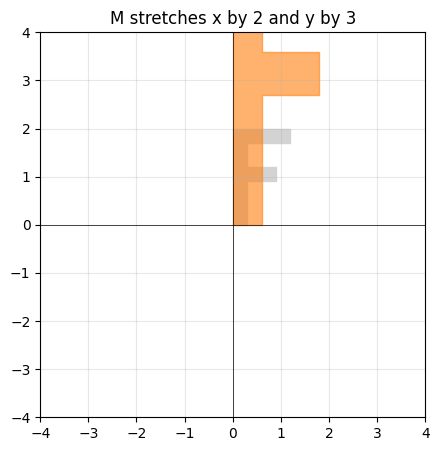

In [3]:
M = np.array([[2, 0],
              [0, 3]])          # stretch x by 2, y by 3
print("M @ (1,1) =", M @ np.array([1, 1]))
print("M @ e1 =", M @ np.array([1, 0]), "(first column)")
print("M @ e2 =", M @ np.array([0, 1]), "(second column)")
show(M, "M stretches x by 2 and y by 3")

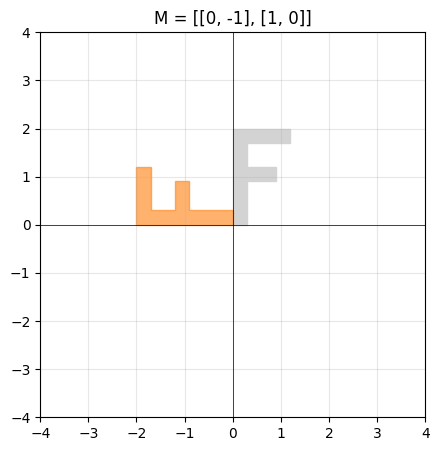

In [4]:
# TRY IT: change the matrix and watch what the F does.  Ideas:
#   [[1, 1], [0, 1]]   a shear (tilts the F)
#   [[0, -1], [1, 0]]  turns everything 90 degrees counterclockwise
#   [[-1, 0], [0, 1]]  mirror left-right
M = np.array([[0, -1],
              [1,  0]])
show(M, f"M = {M.tolist()}")

In [5]:
# linearity: v = 1.5 e1 + 1 e2, so  M v = 1.5 (M e1) + 1 (M e2)
M = np.array([[2, 1], [0.5, 1.5]]); v = np.array([1.5, 1.0])
print("M e1 =", M @ [1, 0], " (column 1)     M e2 =", M @ [0, 1], " (column 2)")
print("M v  =", M @ v, "  =  1.5*column1 + 1*column2 =", 1.5 * M[:, 0] + 1.0 * M[:, 1])

M e1 = [2.  0.5]  (column 1)     M e2 = [1.  1.5]  (column 2)
M v  = [4.   2.25]   =  1.5*column1 + 1*column2 = [4.   2.25]


## 1.3 Composing machines: matrix multiplication
$(AB)v = A(Bv)$: first $B$, then $A$. The order matters, the grouping does not.

AB =
 [[ 1 -1]
 [ 1  0]] 
BA =
 [[ 0 -1]
 [ 1  1]]


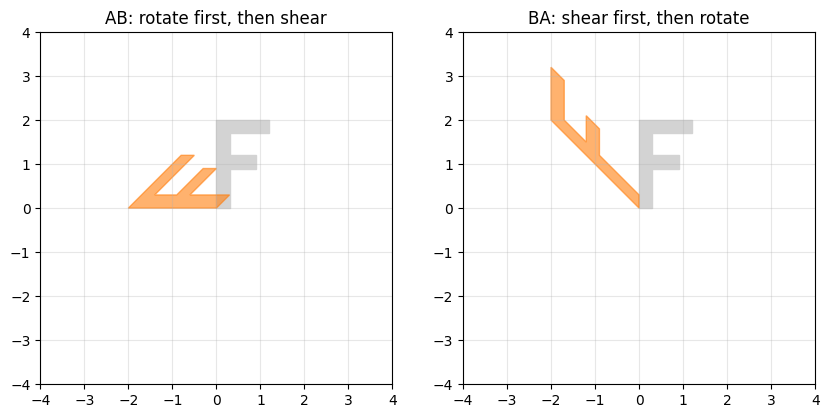

In [6]:
A = np.array([[1, 1], [0, 1]])      # shear
B = np.array([[0, -1], [1, 0]])     # rotate 90 degrees
print("AB =\n", A @ B, "\nBA =\n", B @ A)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (M, name) in zip(axes, [(A @ B, "AB: rotate first, then shear"), (B @ A, "BA: shear first, then rotate")]):
    ax.fill(*F, color="lightgrey"); ax.fill(*(M @ F), color="C1", alpha=.6)
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(name)
plt.show()

In [7]:
rng = np.random.default_rng(0)
A, B, C = rng.normal(size=(3, 3, 3))
print("(AB)C == A(BC)  :", np.allclose((A @ B) @ C, A @ (B @ C)))
print("AB == BA        :", np.allclose(A @ B, B @ A))

(AB)C == A(BC)  : True
AB == BA        : False


## 1.4 The transpose and orthogonal matrices
A matrix is *orthogonal* if $R^\top R = I$: its columns are perpendicular unit vectors, it preserves lengths and angles, and $R^{-1} = R^\top$.

In [8]:
def is_orthogonal(M):
    return np.allclose(M.T @ M, np.eye(M.shape[1]))

th = np.radians(30)
R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
print("R^T R =\n", R.T @ R)
print("orthogonal?", is_orthogonal(R), "   inverse equals transpose?", np.allclose(np.linalg.inv(R), R.T))

shear = np.array([[1, 1], [0, 1]])
print("shear orthogonal?", is_orthogonal(shear), "   (it stretches, so no)")

v = np.array([3., 1.]); print("length before:", np.linalg.norm(v), "  after rotating:", np.linalg.norm(R @ v))

R^T R =
 [[1. 0.]
 [0. 1.]]
orthogonal? True    inverse equals transpose? True
shear orthogonal? False    (it stretches, so no)
length before: 3.1622776601683795   after rotating: 3.162277660168379


## 1.5 Determinant and inverse
The determinant is the area scale factor (negative for a mirror). A matrix with determinant $0$ squashes the plane and has no inverse.

rotation       det =   1.00
mirror         det =  -1.00
stretch x2,y3  det =   6.00
squash flat    det =   0.00


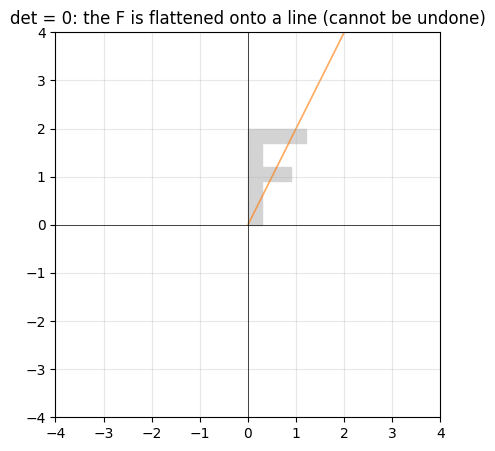

In [9]:
for name, M in [("rotation", R), ("mirror", np.diag([-1, 1])), ("stretch x2,y3", np.diag([2, 3])), ("squash flat", np.array([[1, 2], [2, 4]]))]:
    print(f"{name:14s} det = {np.linalg.det(M):6.2f}")
show(np.array([[1, 2], [2, 4]]), "det = 0: the F is flattened onto a line (cannot be undone)")

In [10]:
M = np.array([[2, 1], [5, 3]])
print("det =", np.linalg.det(M)); print("inverse =\n", np.linalg.inv(M))
a, b, c, d = M.ravel()
print("formula (1/(ad-bc)) [[d,-b],[-c,a]] =\n", np.array([[d, -b], [-c, a]]) / (a*d - b*c))
print("M^-1 M =\n", np.linalg.inv(M) @ M)

det = 1.0000000000000009
inverse =
 [[ 3. -1.]
 [-5.  2.]]
formula (1/(ad-bc)) [[d,-b],[-c,a]] =
 [[ 3. -1.]
 [-5.  2.]]
M^-1 M =
 [[1. 0.]
 [0. 1.]]


## 1.6 Eigenvectors and quadratic forms
An eigenvector is a direction the matrix does not turn: $Mv=\lambda v$. A quadratic form $v^\top M v$ generalizes $cx^2$; it is a bowl when all eigenvalues of the symmetric matrix $M$ are positive (*positive definite*) and a saddle otherwise.

v=[1. 1.]   Mv=[4. 4.]   Mv parallel to v? True
v=[ 1. -1.]   Mv=[ 2. -2.]   Mv parallel to v? True
v=[1. 0.]   Mv=[3. 1.]   Mv parallel to v? False
eigenvalues: [2. 4.] 
eigenvectors (columns):
 [[-0.707  0.707]
 [ 0.707  0.707]]
roots of the characteristic equation  lambda^2 - 6 lambda + 8 = 0: [4. 2.]


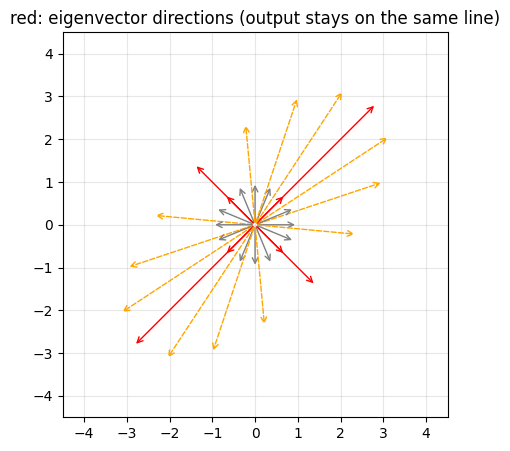

In [11]:
M = np.array([[3., 1.], [1., 3.]])
for v in ([1, 1], [1, -1], [1, 0]):
    v = np.array(v, float); Mv = M @ v
    print(f"v={v}   Mv={Mv}   Mv parallel to v? {np.isclose(Mv[0]*v[1] - Mv[1]*v[0], 0)}")
vals, vecs = np.linalg.eigh(M)
print("eigenvalues:", vals, "\neigenvectors (columns):\n", vecs)
print("roots of the characteristic equation  lambda^2 - 6 lambda + 8 = 0:", np.roots([1, -6, 8]))

# picture: for each direction on the unit circle, the input (grey) and the output Mv (orange)
fig, ax = plt.subplots(figsize=(5, 5))
for a in np.linspace(0, 2*np.pi, 17)[:-1]:
    u = np.array([np.cos(a), np.sin(a)]); Mu = M @ u
    eig = np.isclose(abs(Mu[0]*u[1] - Mu[1]*u[0]), 0)
    ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="red" if eig else "grey"))
    ax.annotate("", xy=Mu, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="red" if eig else "orange", ls="-" if eig else "--"))
ax.set_xlim(-4.5, 4.5); ax.set_ylim(-4.5, 4.5); ax.set_aspect("equal"); ax.grid(alpha=.3)
ax.set_title("red: eigenvector directions (output stays on the same line)"); plt.show()

v^T M v = 15.0    expanded: M11 v1^2 + 2 M12 v1 v2 + M22 v2^2 = 15.0
[[2,1],[1,3]]    eigenvalues [1.382 3.618]  positive definite: True
[[4,-1],[-1,2]]  eigenvalues [1.586 4.414]  positive definite: True
[[1,2],[2,1]]    eigenvalues [-1.  3.]  positive definite: False


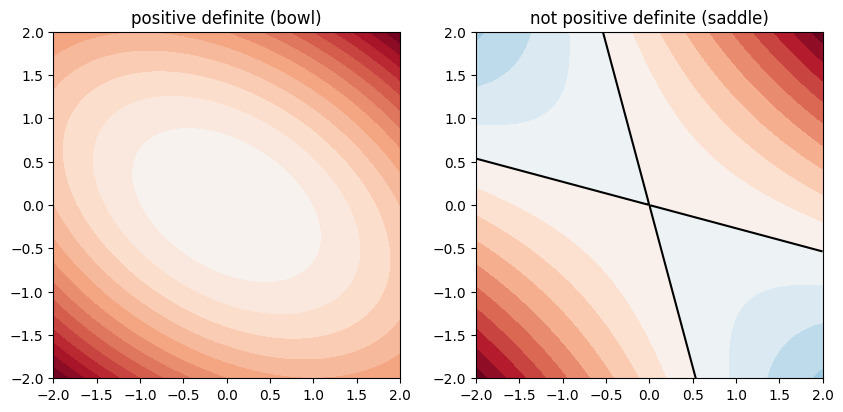

In [12]:
def quad(M, v):
    v = np.asarray(v, float); return v @ M @ v

M = np.array([[2., 1.], [1., 3.]]); v = np.array([2, 1])
print("v^T M v =", quad(M, v), "   expanded: M11 v1^2 + 2 M12 v1 v2 + M22 v2^2 =", M[0,0]*v[0]**2 + 2*M[0,1]*v[0]*v[1] + M[1,1]*v[1]**2)

def is_pos_def(M): return bool(np.all(np.linalg.eigvalsh(M) > 0))
for name, Mx in [("[[2,1],[1,3]]", np.array([[2., 1], [1, 3]])), ("[[4,-1],[-1,2]]", np.array([[4., -1], [-1, 2]])), ("[[1,2],[2,1]]", np.array([[1., 2], [2, 1]]))]:
    print(f"{name:16s} eigenvalues {np.linalg.eigvalsh(Mx).round(3)}  positive definite: {is_pos_def(Mx)}")

# bowl versus saddle
xs = np.linspace(-2, 2, 200); X, Y = np.meshgrid(xs, xs)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, Mx, title in zip(axes, [np.array([[2., 1], [1, 3]]), np.array([[1., 2], [2, 1]])], ["positive definite (bowl)", "not positive definite (saddle)"]):
    Z = Mx[0, 0]*X**2 + 2*Mx[0, 1]*X*Y + Mx[1, 1]*Y**2
    ax.contourf(X, Y, Z, levels=14, cmap="RdBu_r", vmin=-abs(Z).max(), vmax=abs(Z).max()); ax.contour(X, Y, Z, levels=[0], colors="k"); ax.set_aspect("equal"); ax.set_title(title)
plt.show()

## 1.7 Singular values: what a matrix does to a circle
Feed the unit circle through a matrix and you get an ellipse; its semi-axes are the *singular values* $\sigma_1\ge\sigma_2$. The *condition number* $\kappa=\sigma_{\max}/\sigma_{\min}$ says how badly errors are amplified when you solve $Mx=b$.

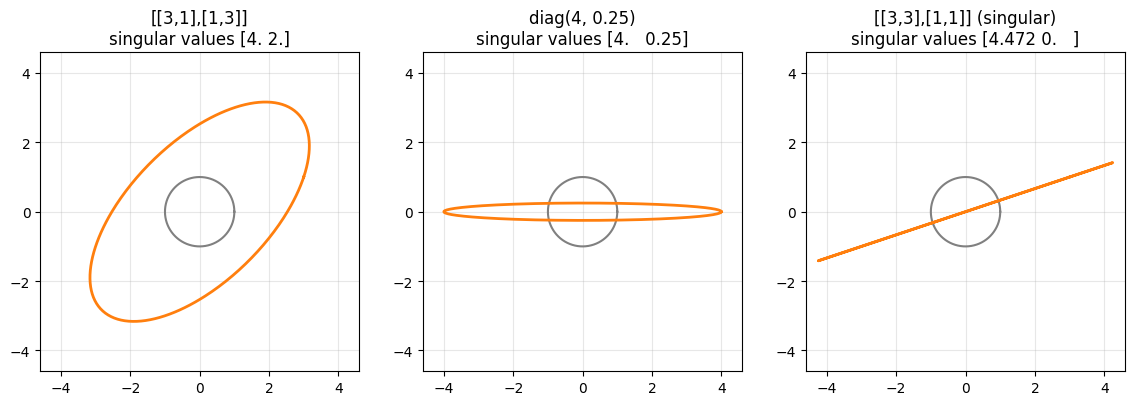

M = U Sigma V^T : True    singular values: [4. 2.]
sigma1 * sigma2 = |det| : 8.0 8.000000000000002


In [13]:
t = np.linspace(0, 2*np.pi, 400); circle = np.vstack([np.cos(t), np.sin(t)])
mats = {"[[3,1],[1,3]]": np.array([[3., 1.], [1., 3.]]), "diag(4, 0.25)": np.diag([4, .25]), "[[3,3],[1,1]] (singular)": np.array([[3., 3.], [1., 1.]])}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, (name, M) in zip(axes, mats.items()):
    s = np.linalg.svd(M, compute_uv=False)
    ax.plot(*circle, color="grey"); ax.plot(*(M @ circle), color="C1", lw=2)
    ax.set_xlim(-4.6, 4.6); ax.set_ylim(-4.6, 4.6); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(f"{name}\nsingular values {s.round(3)}")
plt.show()

U, S, Vt = np.linalg.svd(mats["[[3,1],[1,3]]"])
print("M = U Sigma V^T :", np.allclose(U @ np.diag(S) @ Vt, mats["[[3,1],[1,3]]"]), "   singular values:", S)
print("sigma1 * sigma2 = |det| :", S[0] * S[1], abs(np.linalg.det(mats["[[3,1],[1,3]]"])))

In [14]:
# error amplification: M = diag(5, 0.2), condition number 25
M = np.diag([5, 0.2]); x_true = np.array([1.0, 1.0]); b = M @ x_true
db = 0.1 * np.array([np.cos(0.7), np.sin(0.7)])            # a small error of size 0.1 in b
x_err = np.linalg.solve(M, b + db) - x_true
print("condition number:", np.linalg.cond(M))
print("error in b :", np.linalg.norm(db), "\nerror in x :", np.linalg.norm(x_err), x_err, " <- amplified along the squashed direction")

condition number: 25.0
error in b : 0.1 
error in x : 0.32247186011503376 [0.015 0.322]  <- amplified along the squashed direction


---
## Exercises

> **Exercise 1.1**
>
> Let $M=\begin{bmatrix}0&-1\\1&0\end{bmatrix}$. Find $Me_1$, $Me_2$ and $Mv$ for $v=(3,2)$. What does $M$ do?

In [15]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.1** *(this is the book's Appendix B, checked in code)*

In [16]:
M = np.array([[0, -1], [1, 0]]); v = np.array([3, 2])
print(M @ [1, 0], M @ [0, 1], M @ v); assert np.array_equal(M @ v, [-2, 3])
print("M rotates every vector 90 degrees counterclockwise.")

[0 1] [-1  0] [-2  3]
M rotates every vector 90 degrees counterclockwise.


> **Exercise 1.2**
>
> Compute $AB$ and $BA$ for $A=\begin{bmatrix}1&2\\0&1\end{bmatrix}$, $B=\begin{bmatrix}0&1\\1&0\end{bmatrix}$.

In [17]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.2** *(this is the book's Appendix B, checked in code)*

In [18]:
A = np.array([[1, 2], [0, 1]]); B = np.array([[0, 1], [1, 0]])
print(A @ B, "\n", B @ A); assert np.array_equal(A @ B, [[2, 1], [1, 0]]) and np.array_equal(B @ A, [[0, 1], [1, 2]])
print("not equal")

[[2 1]
 [1 0]] 
 [[0 1]
 [1 2]]
not equal


> **Exercise 1.3**
>
> Is the shear $M=\begin{bmatrix}1&1\\0&1\end{bmatrix}$ orthogonal?

In [19]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.3** *(this is the book's Appendix B, checked in code)*

In [20]:
M = np.array([[1, 1], [0, 1]]); print(M.T @ M); assert not np.allclose(M.T @ M, np.eye(2)) and np.array_equal(M.T @ M, [[1, 1], [1, 2]])
print("No: M^T M is not I.")

[[1 1]
 [1 2]]
No: M^T M is not I.


> **Exercise 1.4**
>
> Find the determinant and inverse of $M=\begin{bmatrix}2&1\\5&3\end{bmatrix}$. Does $\begin{bmatrix}1&3\\2&6\end{bmatrix}$ have an inverse?

In [21]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.4** *(this is the book's Appendix B, checked in code)*

In [22]:
M = np.array([[2, 1], [5, 3]]); print(round(np.linalg.det(M)), np.linalg.inv(M).round(6))
assert np.isclose(np.linalg.det(M), 1) and np.allclose(np.linalg.inv(M), [[3, -1], [-5, 2]])
print("det of [[1,3],[2,6]] =", np.linalg.det(np.array([[1, 3], [2, 6]])), " -> singular, no inverse")

1 [[ 3. -1.]
 [-5.  2.]]
det of [[1,3],[2,6]] = 0.0  -> singular, no inverse


> **Exercise 1.5**
>
> Find the eigenvalues of $M=\begin{bmatrix}4&1\\2&3\end{bmatrix}$.

In [23]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.5** *(this is the book's Appendix B, checked in code)*

In [24]:
vals = np.sort(np.linalg.eigvals(np.array([[4., 1], [2, 3]]))); print(vals); assert np.allclose(vals, [2, 5])
print("(4-l)(3-l) - 2 = l^2 - 7l + 10 = (l-5)(l-2)")

[2. 5.]
(4-l)(3-l) - 2 = l^2 - 7l + 10 = (l-5)(l-2)


> **Exercise 1.6**
>
> For $M=\begin{bmatrix}4&-1\\-1&2\end{bmatrix}$ and $v=(1,3)$ compute $v^\top Mv$.

In [25]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 1.6** *(this is the book's Appendix B, checked in code)*

In [26]:
M = np.array([[4, -1], [-1, 2]]); v = np.array([1, 3]); print(v @ M @ v); assert v @ M @ v == 16
print("4 - 6 + 18 = 16")

16
4 - 6 + 18 = 16


---
**Next:** `02_Rotations.ipynb` (Chapter 2)

*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com